### SIH model

### 0. Importing PyTorch and setting up device- agnostic code

In [ ]:
import torch
from torch import nn

# version
torch.__version__

'2.11.0+cu128'

In [ ]:
# set up device-agnostic code
device ="cuda" if torch.cuda.is_available() else "cpu"
device

'cuda'

## 1. Get data

In [ ]:
!pip install -q datasets

In [ ]:
import requests
import zipfile
from pathlib import Path

data_path = Path("data")
image_path = data_path / "crop_disease"

image_path.mkdir(parents=True, exist_ok=True)

zip_path = data_path / "crop_disease.zip"

url = "https://huggingface.co/datasets/mohanty/PlantVillage/resolve/main/data.zip"

print("Downloading dataset...")

response = requests.get(url)

with open(zip_path, "wb") as f:
    f.write(response.content)

print("Download complete!")

Download complete!


In [ ]:
with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(image_path)

print("Dataset extracted!")

Dataset extracted!


In [ ]:
print(list(image_path.iterdir())[:10])

[PosixPath('data/crop_disease/raw')]


In [ ]:
print(list((image_path / "raw").iterdir()))

[PosixPath('data/crop_disease/raw/segmented'), PosixPath('data/crop_disease/raw/grayscale'), PosixPath('data/crop_disease/raw/color')]


In [ ]:
image_dir = image_path / "raw" / "color"

print(image_dir)

data/crop_disease/raw/color


In [ ]:
class_names = [item.name for item in image_dir.iterdir() if item.is_dir()]

print(f"Number of classes: {len(class_names)}")
print(class_names)

Number of classes: 38
['Potato___healthy', 'Apple___Black_rot', 'Tomato___healthy', 'Soybean___healthy', 'Apple___healthy', 'Apple___Cedar_apple_rust', 'Pepper,_bell___healthy', 'Tomato___Tomato_mosaic_virus', 'Tomato___Target_Spot', 'Squash___Powdery_mildew', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Raspberry___healthy', 'Peach___Bacterial_spot', 'Tomato___Spider_mites Two-spotted_spider_mite', 'Potato___Early_blight', 'Tomato___Septoria_leaf_spot', 'Orange___Haunglongbing_(Citrus_greening)', 'Corn_(maize)___Common_rust_', 'Cherry_(including_sour)___healthy', 'Grape___Esca_(Black_Measles)', 'Grape___healthy', 'Tomato___Late_blight', 'Tomato___Leaf_Mold', 'Strawberry___Leaf_scorch', 'Cherry_(including_sour)___Powdery_mildew', 'Tomato___Early_blight', 'Strawberry___healthy', 'Tomato___Bacterial_spot', 'Pepper,_bell___Bacterial_spot', 'Peach___healthy', 'Blueberry___healthy', 'Grape___Black_rot', 'Tomato___Tomato_Yellow_Leaf_Curl_Virus', 'Corn_(maize)___healthy', 'Apple___Apple_sca

In [ ]:
prediction = 18

print("Predicted class number:", prediction)
print("Predicted disease:", class_names[prediction])

Predicted class number: 18
Predicted disease: Cherry_(including_sour)___healthy


## 2. Data preparation and exploration

In [ ]:
import os
def walk_through_dir(dir_path):
  for dirpath , dirnames,filenames in os.walk(dir_path):
    print(f" there are {len(dirnames)} directories and {len(filenames)} images in {dirpath}")

In [ ]:
walk_through_dir(image_path)

 there are 1 directories and 0 images in data/crop_disease
 there are 3 directories and 0 images in data/crop_disease/raw
 there are 38 directories and 0 images in data/crop_disease/raw/segmented
 there are 0 directories and 152 images in data/crop_disease/raw/segmented/Potato___healthy
 there are 0 directories and 621 images in data/crop_disease/raw/segmented/Apple___Black_rot
 there are 0 directories and 1591 images in data/crop_disease/raw/segmented/Tomato___healthy
 there are 0 directories and 5090 images in data/crop_disease/raw/segmented/Soybean___healthy
 there are 0 directories and 1645 images in data/crop_disease/raw/segmented/Apple___healthy
 there are 0 directories and 275 images in data/crop_disease/raw/segmented/Apple___Cedar_apple_rust
 there are 0 directories and 1478 images in data/crop_disease/raw/segmented/Pepper,_bell___healthy
 there are 0 directories and 373 images in data/crop_disease/raw/segmented/Tomato___Tomato_mosaic_virus
 there are 0 directories and 1404 ima

In [ ]:
# setup train and testing paths
train_dir = image_path/"train"
test_dir = image_path/"test"
train_dir , test_dir

(PosixPath('data/crop_disease/train'), PosixPath('data/crop_disease/test'))

In [ ]:
from pathlib import Path
from sklearn.model_selection import train_test_split

image_dir = Path("data/crop_disease/raw/color")

# Get all image paths
image_paths = list(image_dir.glob("*/*.jpg"))

# Get labels from folder names
labels = [path.parent.name for path in image_paths]

print("Total images:", len(image_paths))
print("Total classes:", len(set(labels)))

Total images: 1500
Total classes: 8


In [ ]:
from collections import Counter

class_counts = Counter(labels)

for class_name, count in class_counts.items():
    print(class_name, ":", count)

Tomato___healthy : 1
Pepper,_bell___healthy : 1
Squash___Powdery_mildew : 22
Tomato___Late_blight : 152
Strawberry___Leaf_scorch : 1
Corn_(maize)___healthy : 1141
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot : 67
Corn_(maize)___Northern_Leaf_Blight : 115


In [ ]:
print(image_dir)
print(image_dir.resolve())

data/crop_disease/raw/color
/content/data/crop_disease/raw/color


In [ ]:
for folder in image_dir.iterdir():
    if folder.is_dir():
        print(folder.name)

Potato___healthy
Apple___Black_rot
Tomato___healthy
Soybean___healthy
Apple___healthy
Apple___Cedar_apple_rust
Pepper,_bell___healthy
Tomato___Tomato_mosaic_virus
Tomato___Target_Spot
Squash___Powdery_mildew
Grape___Leaf_blight_(Isariopsis_Leaf_Spot)
Raspberry___healthy
Peach___Bacterial_spot
Tomato___Spider_mites Two-spotted_spider_mite
Potato___Early_blight
Tomato___Septoria_leaf_spot
Orange___Haunglongbing_(Citrus_greening)
Corn_(maize)___Common_rust_
Cherry_(including_sour)___healthy
Grape___Esca_(Black_Measles)
Grape___healthy
Tomato___Late_blight
Tomato___Leaf_Mold
Strawberry___Leaf_scorch
Cherry_(including_sour)___Powdery_mildew
Tomato___Early_blight
Strawberry___healthy
Tomato___Bacterial_spot
Pepper,_bell___Bacterial_spot
Peach___healthy
Blueberry___healthy
Grape___Black_rot
Tomato___Tomato_Yellow_Leaf_Curl_Virus
Corn_(maize)___healthy
Apple___Apple_scab
Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot
Corn_(maize)___Northern_Leaf_Blight
Potato___Late_blight


In [ ]:
print("Number of class folders:", len([
    folder for folder in image_dir.iterdir()
    if folder.is_dir()
]))

Number of class folders: 38


In [ ]:
image_paths = [
    path for path in image_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("Total images:", len(image_paths))

Total images: 54305


In [ ]:
labels = [path.parent.name for path in image_paths]

print("Total classes:", len(set(labels)))

Total classes: 38


In [ ]:
image_paths = [
    path for path in image_dir.rglob("*")
    if path.is_file() and path.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("Total images:", len(image_paths))

Total images: 54305


In [ ]:
labels = [path.parent.name for path in image_paths]

print("Total classes:", len(set(labels)))

Total classes: 38


In [ ]:
from collections import Counter

class_counts = Counter(labels)

for class_name, count in class_counts.items():
    print(class_name, ":", count)

Potato___healthy : 152
Apple___Black_rot : 621
Tomato___healthy : 1591
Soybean___healthy : 5090
Apple___healthy : 1645
Apple___Cedar_apple_rust : 275
Pepper,_bell___healthy : 1478
Tomato___Tomato_mosaic_virus : 373
Tomato___Target_Spot : 1404
Squash___Powdery_mildew : 1835
Grape___Leaf_blight_(Isariopsis_Leaf_Spot) : 1076
Raspberry___healthy : 371
Peach___Bacterial_spot : 2297
Tomato___Spider_mites Two-spotted_spider_mite : 1676
Potato___Early_blight : 1000
Tomato___Septoria_leaf_spot : 1771
Orange___Haunglongbing_(Citrus_greening) : 5507
Corn_(maize)___Common_rust_ : 1192
Cherry_(including_sour)___healthy : 854
Grape___Esca_(Black_Measles) : 1383
Grape___healthy : 423
Tomato___Late_blight : 1909
Tomato___Leaf_Mold : 952
Strawberry___Leaf_scorch : 1109
Cherry_(including_sour)___Powdery_mildew : 1052
Tomato___Early_blight : 1000
Strawberry___healthy : 456
Tomato___Bacterial_spot : 2127
Pepper,_bell___Bacterial_spot : 997
Peach___healthy : 360
Blueberry___healthy : 1502
Grape___Black_rot

In [ ]:
from sklearn.model_selection import train_test_split

train_paths, test_paths, train_labels, test_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.2,
    random_state=42,
    stratify=labels
)

print("Train:", len(train_paths))
print("Test:", len(test_paths))

Train: 43444
Test: 10861


### Creating sepreate folder for test and train


In [ ]:
from pathlib import Path
import shutil

train_dir = Path("data/crop_disease/train")
test_dir = Path("data/crop_disease/test")

train_dir.mkdir(parents=True, exist_ok=True)
test_dir.mkdir(parents=True, exist_ok=True)

# Create class folders
for label in set(train_labels):
    (train_dir / label).mkdir(parents=True, exist_ok=True)
    (test_dir / label).mkdir(parents=True, exist_ok=True)

print("Folders created!")

Folders created!


In [ ]:
for image_path, label in zip(train_paths, train_labels):
    destination = train_dir / label / image_path.name
    shutil.copy2(image_path, destination)

print("Training images copied!")

Training images copied!


In [ ]:
for image_path, label in zip(test_paths, test_labels):
    destination = test_dir / label / image_path.name
    shutil.copy2(image_path, destination)

print("Test images copied!")

Test images copied!


In [ ]:
from pathlib import Path

image_files = [
    p for p in Path("/content").rglob("*")
    if p.is_file() and p.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print(image_files[0])

/content/data/crop_disease/test/Potato___healthy/2d98cbc8-cbe6-423c-b2ab-3f7f8bcea5d5___RS_HL 1945.JPG


## 2.1 Visualizing and image

In [ ]:
from pathlib import Path

image_path = Path("/content/data/crop_disease/raw/color")

In [ ]:
image_path_list = [
    path for path in image_path.rglob("*")
    if path.is_file() and path.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

print("Number of images:", len(image_path_list))

Number of images: 54305


/content/data/crop_disease/raw/color/Tomato___healthy/902d49e5-febf-4970-b0fb-99a57e8e284b___GH_HL Leaf 179.JPG
Tomato___healthy
Random image path : /content/data/crop_disease/raw/color/Tomato___healthy/902d49e5-febf-4970-b0fb-99a57e8e284b___GH_HL Leaf 179.JPG
Image class :Tomato___healthy
Image height : 256
Image width : 256
RGB


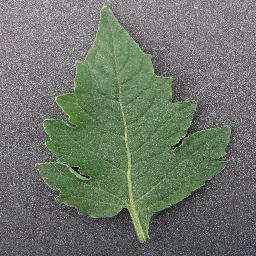

In [ ]:
import random
from PIL import Image



# get all images
image_path_list = [
    path for path in image_path.rglob("*")
    if path.is_file() and path.suffix.lower() in [".jpg", ".jpeg", ".png"]
]

# 2. a random image path
random_image_path = random.choice(image_path_list)
print(random_image_path)

# 3 . get image class from path name
image_class = random_image_path.parent.stem
print(image_class)

# 4. open image
img = Image.open(random_image_path)

# 5. print metadata
print(f"Random image path : {random_image_path}")
print(f"Image class :{image_class}")
print(f"Image height : {img.height}")
print(f"Image width : {img.width}")
print(img.mode)
img


(np.float64(-0.5), np.float64(255.5), np.float64(255.5), np.float64(-0.5))

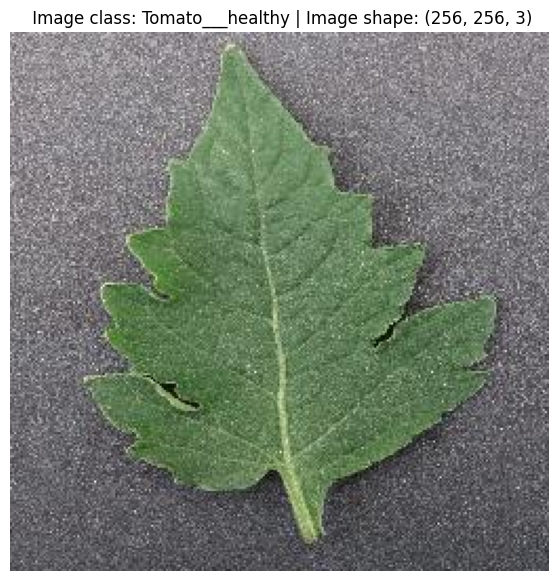

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Turn the image into and arrya
img_as_array = np.asarray(img)

# plot the image with matplotlib
plt.figure(figsize = (10,7))
plt.imshow(img_as_array)
plt.title(f" Image class: {image_class} | Image shape: {img_as_array.shape}")
plt.axis(False)

array([[[151, 146, 150],
        [205, 200, 204],
        [136, 131, 135],
        ...,
        [148, 143, 149],
        [166, 161, 167],
        [115, 110, 116]],

       [[147, 142, 146],
        [121, 116, 120],
        [156, 151, 155],
        ...,
        [118, 113, 119],
        [119, 114, 120],
        [159, 154, 160]],

       [[149, 144, 148],
        [216, 211, 215],
        [153, 148, 152],
        ...,
        [141, 136, 142],
        [142, 137, 143],
        [132, 127, 133]],

       ...,

       [[ 85,  84,  89],
        [103, 102, 107],
        [102, 101, 106],
        ...,
        [ 89,  90,  95],
        [ 70,  71,  76],
        [ 85,  86,  91]],

       [[ 76,  75,  80],
        [ 79,  78,  83],
        [ 52,  51,  56],
        ...,
        [ 72,  73,  78],
        [ 78,  79,  84],
        [ 77,  78,  83]],

       [[ 78,  77,  82],
        [ 95,  94,  99],
        [ 96,  95, 100],
        ...,
        [ 81,  82,  87],
        [ 65,  66,  71],
        [ 72,  73,  78]]], dtype=uint8)
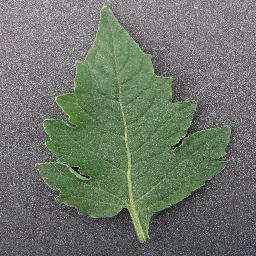

In [ ]:
img_as_array

## 3. Transforming data

In [ ]:
import torch
from torch.utils.data import DataLoader
from torchvision import datasets , transforms

### 3.1 Transforming data with torchvision.transforms

In [ ]:
# write a transform for image
data_transform = transforms.Compose([
    #Resize our images to 64 x 64
    transforms.Resize(size = (128,128)),
    # flip the image randomly
    transforms.RandomHorizontalFlip(p=0.5),
    # Turn the image into tensor
    transforms.ToTensor()
])

In [ ]:
data_transform(img).dtype

torch.float32

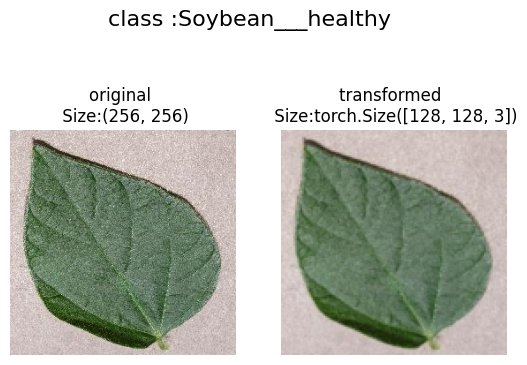

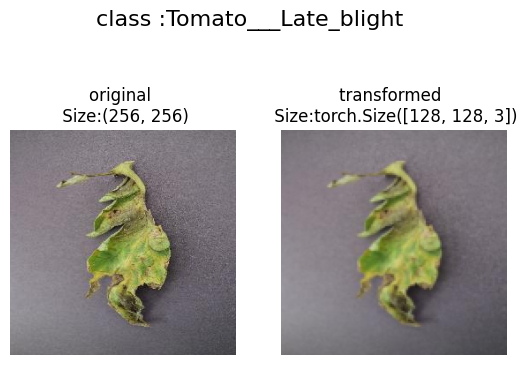

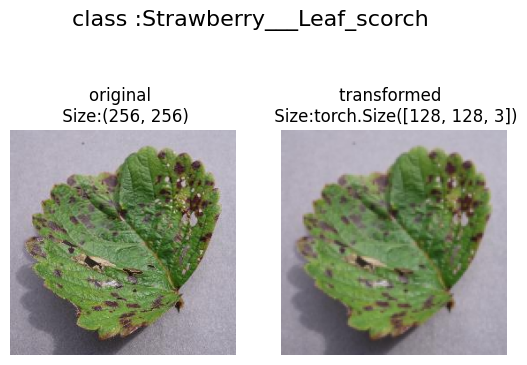

In [ ]:
def plot_transformed_images(image_paths,transform,n=3,seed = None):
  #selct random images nad transform and plot them
  if seed:
    random.seed(seed)
  random_image_paths = random.sample(image_paths , k=n)
  for image_path in random_image_paths:
    with Image.open(image_path) as f:
      fig,ax = plt.subplots(nrows = 1, ncols = 2)
      ax[0].imshow(f)
      ax[0].set_title(f"original \n Size:{f.size}")
      ax[0].axis(False)

      # transform and plot target image
      transformed_image = transform(f).permute(1,2,0) # change shape for matplotlib (C,H,W)->(H,W,C)
      ax[1].imshow(transformed_image)
      ax[1].set_title(f"transformed \n Size:{transformed_image.shape}")
      ax[1].axis(False)

      fig.suptitle(f"class :{image_path.parent.stem}",fontsize = 16)
plot_transformed_images(image_paths = image_path_list,
                        transform = data_transform,
                        n =3,
                        seed = None)




In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cuda


### 4. Loading image data using ImageFolder

* torchvision.datasets.ImageFolder

In [ ]:
# use ImageFolder to create datasets
from torchvision import datasets
train_data = datasets.ImageFolder(root = train_dir,
                                  transform = data_transform, # transform dataset
                                  target_transform = None) # a trabform for the data
test_data = datasets.ImageFolder(root = test_dir,
                                 transform = data_transform,
                                 target_transform = None)
train_data,test_data

(Dataset ImageFolder
     Number of datapoints: 43444
     Root location: data/crop_disease/train
     StandardTransform
 Transform: Compose(
                Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ),
 Dataset ImageFolder
     Number of datapoints: 10861
     Root location: data/crop_disease/test
     StandardTransform
 Transform: Compose(
                Resize(size=(128, 128), interpolation=bilinear, max_size=None, antialias=True)
                RandomHorizontalFlip(p=0.5)
                ToTensor()
            ))

In [ ]:
# Get class name as list
class_names = train_data.classes
class_names

['Apple___Apple_scab',
 'Apple___Black_rot',
 'Apple___Cedar_apple_rust',
 'Apple___healthy',
 'Blueberry___healthy',
 'Cherry_(including_sour)___Powdery_mildew',
 'Cherry_(including_sour)___healthy',
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot',
 'Corn_(maize)___Common_rust_',
 'Corn_(maize)___Northern_Leaf_Blight',
 'Corn_(maize)___healthy',
 'Grape___Black_rot',
 'Grape___Esca_(Black_Measles)',
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)',
 'Grape___healthy',
 'Orange___Haunglongbing_(Citrus_greening)',
 'Peach___Bacterial_spot',
 'Peach___healthy',
 'Pepper,_bell___Bacterial_spot',
 'Pepper,_bell___healthy',
 'Potato___Early_blight',
 'Potato___Late_blight',
 'Potato___healthy',
 'Raspberry___healthy',
 'Soybean___healthy',
 'Squash___Powdery_mildew',
 'Strawberry___Leaf_scorch',
 'Strawberry___healthy',
 'Tomato___Bacterial_spot',
 'Tomato___Early_blight',
 'Tomato___Late_blight',
 'Tomato___Leaf_Mold',
 'Tomato___Septoria_leaf_spot',
 'Tomato___Spider_mites Two-spotted_

In [ ]:
# Get class names as dict
class_dict = train_data.class_to_idx
class_dict

{'Apple___Apple_scab': 0,
 'Apple___Black_rot': 1,
 'Apple___Cedar_apple_rust': 2,
 'Apple___healthy': 3,
 'Blueberry___healthy': 4,
 'Cherry_(including_sour)___Powdery_mildew': 5,
 'Cherry_(including_sour)___healthy': 6,
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 7,
 'Corn_(maize)___Common_rust_': 8,
 'Corn_(maize)___Northern_Leaf_Blight': 9,
 'Corn_(maize)___healthy': 10,
 'Grape___Black_rot': 11,
 'Grape___Esca_(Black_Measles)': 12,
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)': 13,
 'Grape___healthy': 14,
 'Orange___Haunglongbing_(Citrus_greening)': 15,
 'Peach___Bacterial_spot': 16,
 'Peach___healthy': 17,
 'Pepper,_bell___Bacterial_spot': 18,
 'Pepper,_bell___healthy': 19,
 'Potato___Early_blight': 20,
 'Potato___Late_blight': 21,
 'Potato___healthy': 22,
 'Raspberry___healthy': 23,
 'Soybean___healthy': 24,
 'Squash___Powdery_mildew': 25,
 'Strawberry___Leaf_scorch': 26,
 'Strawberry___healthy': 27,
 'Tomato___Bacterial_spot': 28,
 'Tomato___Early_blight': 29,
 'Toma

In [ ]:
# check len of dataset
len(train_data),len(test_data)

(43444, 10861)

In [ ]:
train_data.samples[0]

('data/crop_disease/train/Apple___Apple_scab/00075aa8-d81a-4184-8541-b692b78d398a___FREC_Scab 3335.JPG',
 0)

In [ ]:
# Index on the train_data dataset
img , label = train_data[0][0],train_data[0][1]
print(f"Image tensor:\n {img}")
print(f"Image shape : {img.shape}")
print(f"Image datatype : {img.dtype}")
print(f"Image label:{label}")
print(f"Label datatype :{type(label)}")

Image tensor:
 tensor([[[0.6588, 0.6549, 0.6510,  ..., 0.7373, 0.7333, 0.7176],
         [0.6627, 0.6588, 0.6510,  ..., 0.7373, 0.7373, 0.7294],
         [0.6667, 0.6667, 0.6667,  ..., 0.7333, 0.7294, 0.7294],
         ...,
         [0.4118, 0.4039, 0.3961,  ..., 0.4863, 0.4902, 0.4902],
         [0.4000, 0.4078, 0.4000,  ..., 0.4941, 0.4980, 0.4980],
         [0.4000, 0.4039, 0.4000,  ..., 0.4706, 0.4784, 0.4824]],

        [[0.6431, 0.6392, 0.6353,  ..., 0.7255, 0.7216, 0.7059],
         [0.6471, 0.6431, 0.6353,  ..., 0.7255, 0.7255, 0.7176],
         [0.6510, 0.6510, 0.6510,  ..., 0.7216, 0.7176, 0.7176],
         ...,
         [0.3725, 0.3647, 0.3569,  ..., 0.4235, 0.4275, 0.4275],
         [0.3608, 0.3686, 0.3608,  ..., 0.4314, 0.4353, 0.4353],
         [0.3608, 0.3647, 0.3608,  ..., 0.4078, 0.4157, 0.4196]],

        [[0.7725, 0.7686, 0.7647,  ..., 0.8392, 0.8353, 0.8196],
         [0.7765, 0.7725, 0.7647,  ..., 0.8392, 0.8392, 0.8314],
         [0.7804, 0.7804, 0.7804,  ..., 0.8

# 4.1 Turn loaded images into DataLoader

In [ ]:
# Turn train and test datsets into DataLoaders
from torch.utils.data import DataLoader

BATCH_SIZE = 32
train_dataloader = DataLoader(dataset = train_data,
                          batch_size = BATCH_SIZE,
                          num_workers = 0,
                          shuffle = True)
test_dataloader = DataLoader(dataset = test_data,
                          batch_size = BATCH_SIZE,
                          num_workers = 0,
                          shuffle = False)
train_dataloader,test_dataloader

(<torch.utils.data.dataloader.DataLoader at 0x7b2c77c712b0>,
 <torch.utils.data.dataloader.DataLoader at 0x7b2c8b3447d0>)

In [ ]:
len(train_dataloader),len(test_dataloader)

(1358, 340)

In [ ]:
img,label = next(iter(train_dataloader))
print(f"Image shape :{img.shape} ->[batch_size,color_channels,height,width]")
print(f"Label shape:{label.shape}")

Image shape :torch.Size([32, 3, 128, 128]) ->[batch_size,color_channels,height,width]
Label shape:torch.Size([32])


### Model

## 7.1 Create  model clas

In [ ]:
len(train_dataloader),len(test_dataloader)

(1358, 340)

In [ ]:
import torch
import torch.nn as nn


def get_crop_disease_model(num_classes=38):
    """
    CNN model for crop disease classification.
    Input: RGB image of size 224x224
    Output: num_classes disease classes
    """

    model = nn.Sequential(

        # CNN Block 1
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.BatchNorm2d(32),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # CNN Block 2
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.BatchNorm2d(64),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # CNN Block 3
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.BatchNorm2d(128),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # CNN Block 4
        nn.Conv2d(128, 256, kernel_size=3, padding=1),
        nn.BatchNorm2d(256),
        nn.ReLU(),
        nn.MaxPool2d(2),

        # Convert feature maps to fixed-size features
        nn.AdaptiveAvgPool2d((1, 1)),

        # Linear Classifier
        nn.Flatten(),
        nn.Linear(256, 128),
        nn.ReLU(),
        nn.Dropout(0.5),

        # Final classifier
        nn.Linear(128, num_classes)
    )

    return model

In [ ]:

model = get_crop_disease_model(num_classes=38)

print(model)

#Setup loss and optimizer
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=0.001, weight_decay=1e-4)


Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 46.1MB/s]


### Loss function and optimizer

### Train and test
* train_step()
* test_step()

In [ ]:
from tqdm.auto import tqdm

def train_step(model, dataloader, loss_fn, optimizer, device):

    model.train()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    progress_bar = tqdm(
        dataloader,
        desc="Training batches",
        leave=False
    )

    for X, y in progress_bar:

        X = X.to(device, non_blocking=True)
        y = y.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        y_pred = model(X)

        loss = loss_fn(y_pred, y)

        loss.backward()
        optimizer.step()

        batch_size = X.size(0)

        total_loss += loss.item() * batch_size

        predicted_class = y_pred.argmax(dim=1)
        total_correct += (predicted_class == y).sum().item()
        total_samples += batch_size

        # Show current batch loss
        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    train_loss = total_loss / total_samples
    train_acc = total_correct / total_samples

    return train_loss, train_acc

In [ ]:
def test_step(model, dataloader, loss_fn, device):
    """
    Evaluates the model on the test/validation dataset.

    Returns:
        test_loss: Average test loss
        test_acc: Test accuracy
    """

    # Evaluation mode
    model.eval()

    total_loss = 0.0
    total_correct = 0
    total_samples = 0

    # No gradient calculation during testing
    with torch.inference_mode():

        for X, y in dataloader:

            # Move data to CPU/GPU
            X = X.to(device, non_blocking=True)
            y = y.to(device, non_blocking=True)

            # Forward pass
            y_pred = model(X)

            # Calculate loss
            loss = loss_fn(y_pred, y)

            # Statistics
            batch_size = X.size(0)

            total_loss += loss.item() * batch_size

            # Get predicted class
            predicted_class = torch.argmax(y_pred, dim=1)

            total_correct += (
                predicted_class == y
            ).sum().item()

            total_samples += batch_size

    # Average loss
    test_loss = total_loss / total_samples

    # Accuracy
    test_acc = total_correct / total_samples

    return test_loss, test_acc

### combine train step and test step

In [ ]:
from tqdm.auto import tqdm
import torch

def train_model(
    model,
    train_dataloader,
    test_dataloader,
    loss_fn,
    optimizer,
    device,
    epochs=10
):

    results = {
        "train_loss": [],
        "train_acc": [],
        "test_loss": [],
        "test_acc": []
    }

    for epoch in tqdm(range(epochs), desc="Training"):

        # Train
        train_loss, train_acc = train_step(
            model=model,
            dataloader=train_dataloader,
            loss_fn=loss_fn,
            optimizer=optimizer,
            device=device
        )

        # Test
        test_loss, test_acc = test_step(
            model=model,
            dataloader=test_dataloader,
            loss_fn=loss_fn,
            device=device
        )

        # Store results
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

        # Update tqdm description
        tqdm.write(
            f"Epoch {epoch + 1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc * 100:.2f}% | "
            f"Test Loss: {test_loss:.4f} | "
            f"Test Acc: {test_acc * 100:.2f}%"
        )

    return results

In [ ]:
results = train_model(
    model=model,
    train_dataloader=train_dataloader,
    test_dataloader=test_dataloader,
    loss_fn=loss_fn,
    optimizer=optimizer,
    device=device,
    epochs=10
)

Training:   0%|          | 0/10 [00:00<?, ?it/s]

Training batches:   0%|          | 0/1358 [00:00<?, ?it/s]

Epoch 1/10 | Train Loss: 0.0511 | Train Acc: 98.56% | Test Loss: 0.1646 | Test Acc: 96.04%


Training batches:   0%|          | 0/1358 [00:00<?, ?it/s]

Epoch 2/10 | Train Loss: 0.0480 | Train Acc: 98.63% | Test Loss: 0.0922 | Test Acc: 97.52%


...

Epoch 8/10 | Train Loss: 0.0334 | Train Acc: 99.02% | Test Loss: 0.0904 | Test Acc: 97.93%


Training batches:   0%|          | 0/1358 [00:00<?, ?it/s]

Epoch 9/10 | Train Loss: 0.0308 | Train Acc: 99.09% | Test Loss: 0.1360 | Test Acc: 96.69%


Training batches:   0%|          | 0/1358 [00:00<?, ?it/s]

Epoch 10/10 | Train Loss: 0.0336 | Train Acc: 99.06% | Test Loss: 0.2794 | Test Acc: 94.43%


Saving strawberry2.png to strawberry2 (4).png


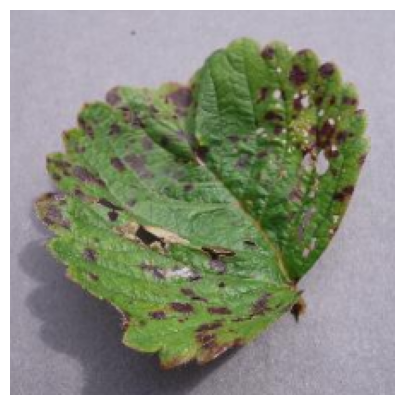

Predicted Class Index: 26
Confidence: 89.53%
class name: Strawberry___Leaf_scorch


In [ ]:
from google.colab import files
from PIL import Image
import torch
from torchvision import transforms
import matplotlib.pyplot as plt

# 1. Upload sample image
uploaded = files.upload()

image_path = list(uploaded.keys())[0]

# 2. Open image
image = Image.open(image_path).convert("RGB")

# 3. Show image
plt.figure(figsize=(5, 5))
plt.imshow(image)
plt.axis("off")
plt.show()

# 4. Preprocess image
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

image_tensor = transform(image).unsqueeze(0)

# 5. Move image to same device as model
image_tensor = image_tensor.to(device)

# 6. Prediction
model.eval()

with torch.inference_mode():
    output = model(image_tensor)

    probabilities = torch.softmax(output, dim=1)

    confidence, predicted = torch.max(
        probabilities,
        dim=1
    )

# 7. Get prediction
predicted_index = predicted.item()
confidence_value = confidence.item()



print("Predicted Class Index:", predicted_index)

print(
    f"Confidence: {confidence_value * 100:.2f}%"
)
print("class name:",class_names[predicted_index])

### save


In [ ]:
torch.save(model.state_dict(), "/content/model.pth")
print("Model saved!")

Model saved!


In [ ]:
from google.colab import files

files.download("/content/model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>